# KDP from PHIDP: three published methods on S, C and X band

**radar-wow stage 3.** Methods (all in `radarwow.kdp`, same interface):

| algorithm | paper | idea |
|---|---|---|
| `Vulpiani2012KDP` | Vulpiani et al. 2012, JAMC, doi:10.1175/JAMC-D-10-05024.1 | window derivative, physical-range check, rebuild PHIDP, iterate |
| `Giangrande2013LP` | Giangrande, McGraw & Lei 2013, JTECH, doi:10.1175/JTECH-D-12-00147.1 | L1 fit with monotonic PHIDP (KDP ≥ 0), linear programming |
| `MovingRegressionKDP` | Wolfensberger et al. 2021, AMT, doi:10.5194/amt-14-3169-2021 (App. A) | median filter + moving linear regression |

Every source needs PHIDP preparation first (signal + rain mask, unfold, **sign convention**,
system offset), done once in `radarwow.kdp.phase`. We test on (1) synthetic rays with known
truth, then (2) free real data for each band.

In [1]:
# Colab: uncomment to install
!pip install -q "git+https://github.com/radar-wow/radarwow-core" "git+https://github.com/radar-wow/radarwow-kdp"

zsh:1: command not found: pip


In [2]:
import time
import warnings

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from IPython.display import Markdown, display

from radarwow.core import diagnose, load_sample
from radarwow.core.plotting import ppi
from radarwow.core.testing import synthetic_ray
from radarwow.kdp import Giangrande2013LP, MovingRegressionKDP, Vulpiani2012KDP

FIG = "../docs/figures"
METHODS = {"Vulpiani 2012": Vulpiani2012KDP, "Giangrande 2013 LP": Giangrande2013LP, "Moving regression": MovingRegressionKDP}

## 1. Synthetic rays: known truth
Two rain cells, 3° PHIDP noise, a 15° backscatter-phase (δ) bump in the first core, 150° system
offset and storage wrapped to ±180°: the problems real radars have.

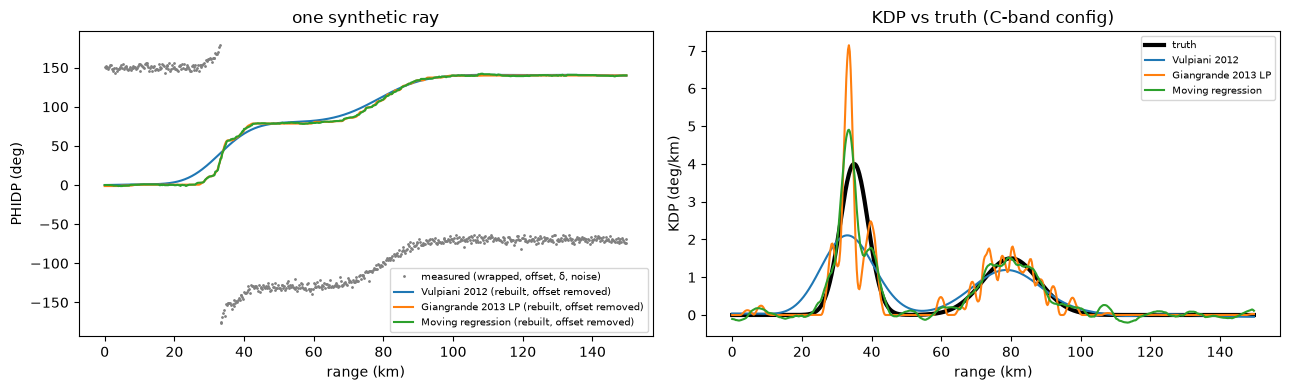

| band config | method | RMSE (°/km) | bias (°/km) | min KDP |
|---|---|---|---|---|
| S | Vulpiani 2012 | 0.44 | -0.01 | -0.26 |
| S | Giangrande 2013 LP | 0.46 | +0.01 | -0.00 |
| S | Moving regression | 0.29 | -0.00 | -1.43 |
| C | Vulpiani 2012 | 0.44 | -0.01 | -0.26 |
| C | Giangrande 2013 LP | 0.46 | +0.01 | -0.00 |
| C | Moving regression | 0.29 | -0.00 | -1.43 |
| X | Vulpiani 2012 | 0.33 | -0.01 | -0.51 |
| X | Giangrande 2013 LP | 0.46 | +0.01 | -0.00 |
| X | Moving regression | 0.29 | -0.00 | -1.43 |

In [3]:
def ray_dataset(n_rays=12, **kw):
    rays = [synthetic_ray(seed=s, **kw) for s in range(n_rays)]
    psi = np.stack([r[1] for r in rays])
    ds = xr.Dataset({"PHIDP": (("azimuth", "range"), psi),
                     "DBZH": (("azimuth", "range"), np.full(psi.shape, 35.0)),
                     "RHOHV": (("azimuth", "range"), np.full(psi.shape, 0.99)),
                     "SNRH": (("azimuth", "range"), np.full(psi.shape, 30.0))},
                    coords={"azimuth": np.arange(n_rays, dtype=float), "range": rays[0][0] * 1e3 + 125.0})
    return ds, np.stack([r[3] for r in rays]), rays[0][0]


cells = dict(centers=(35.0, 80.0), widths=(4.0, 8.0), peaks=(4.0, 1.5))
ds_syn, truth, r_km = ray_dataset(offset=150.0, wrap=True, noise=3.0, delta_peak=15.0, **cells)
rows = ["| band config | method | RMSE (°/km) | bias (°/km) | min KDP |", "|---|---|---|---|---|"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(r_km, ds_syn["PHIDP"].values[0], ".", ms=2, color="grey", label="measured (wrapped, offset, δ, noise)")
ax[1].plot(r_km, truth[0], "k", lw=3, label="truth")
for band in ("S", "C", "X"):
    for label, cls in METHODS.items():
        out = cls()(ds_syn, band=band)
        k = out["KDP"].values
        rows.append(f"| {band} | {label} | {np.sqrt(np.nanmean((k - truth) ** 2)):.2f} | {np.nanmean(k - truth):+.2f} | {np.nanmin(k):.2f} |")
        if band == "C":
            ax[1].plot(r_km, k[0], label=label)
            ax[0].plot(r_km, out["PHIDP_REC"].values[0], label=f"{label} (rebuilt, offset removed)")
ax[0].set(xlabel="range (km)", ylabel="PHIDP (deg)", title="one synthetic ray")
ax[1].set(xlabel="range (km)", ylabel="KDP (deg/km)", title="KDP vs truth (C-band config)")
for a in ax:
    a.legend(fontsize=7)
fig.tight_layout()
fig.savefig(f"{FIG}/01_synthetic.png", dpi=110)
plt.show()
display(Markdown("\n".join(rows)))

Band configs differ only in the window length and physical KDP range (`radarwow/core/bands/*.toml`),
so S and C give identical numbers here. Moving regression has the lowest RMSE but the most negative
KDP (it follows the δ bump); LP never goes negative (monotonic constraint); Vulpiani's 7 km window
smooths the sharp first cell (the shorter X-band window does better).

## 2. Real data: one sample per band
Each source first goes through `diagnose()`. The PHIDP problems differ per radar:

In [4]:
samples = {"S": "nexrad_ktlx_s", "C": "arm_csapr2_c", "X": "arm_xsapr_x"}
data = {}
for band, name in samples.items():
    dt = load_sample(name)
    rep = diagnose(dt)
    data[band] = dt[rep.sweep].to_dataset()
    lines = [f"- [{f.severity}] {f.message}" for f in rep.findings if f.topic == "PHIDP"]
    display(Markdown(f"**{name}** (band {band}), {rep.sweep}: PHIDP source field `{data[band]['PHIDP'].attrs.get('radarwow_source_name')}`\n" + "\n".join(lines)))

**nexrad_ktlx_s** (band S), sweep_0: PHIDP source field `PHIDP`
- [fix] system PHIDP offset ~36 deg (median of first rain gates)
- [fix] 38 rays with a > 180 deg drop (folding)

**arm_csapr2_c** (band C), sweep_0: PHIDP source field `differential_phase`
- [fix] system PHIDP offset ~197 deg (median of first rain gates)
- [fix] 36 rays with a > 180 deg drop (folding)
- [fix] PHIDP decreases with range in rain on 92% of rays (reversed sign convention)

**arm_xsapr_x** (band X), sweep_0: PHIDP source field `dp_phase_shift`
- [fix] system PHIDP offset ~119 deg (median of first rain gates)
- [fix] 45 rays with a > 180 deg drop (folding)

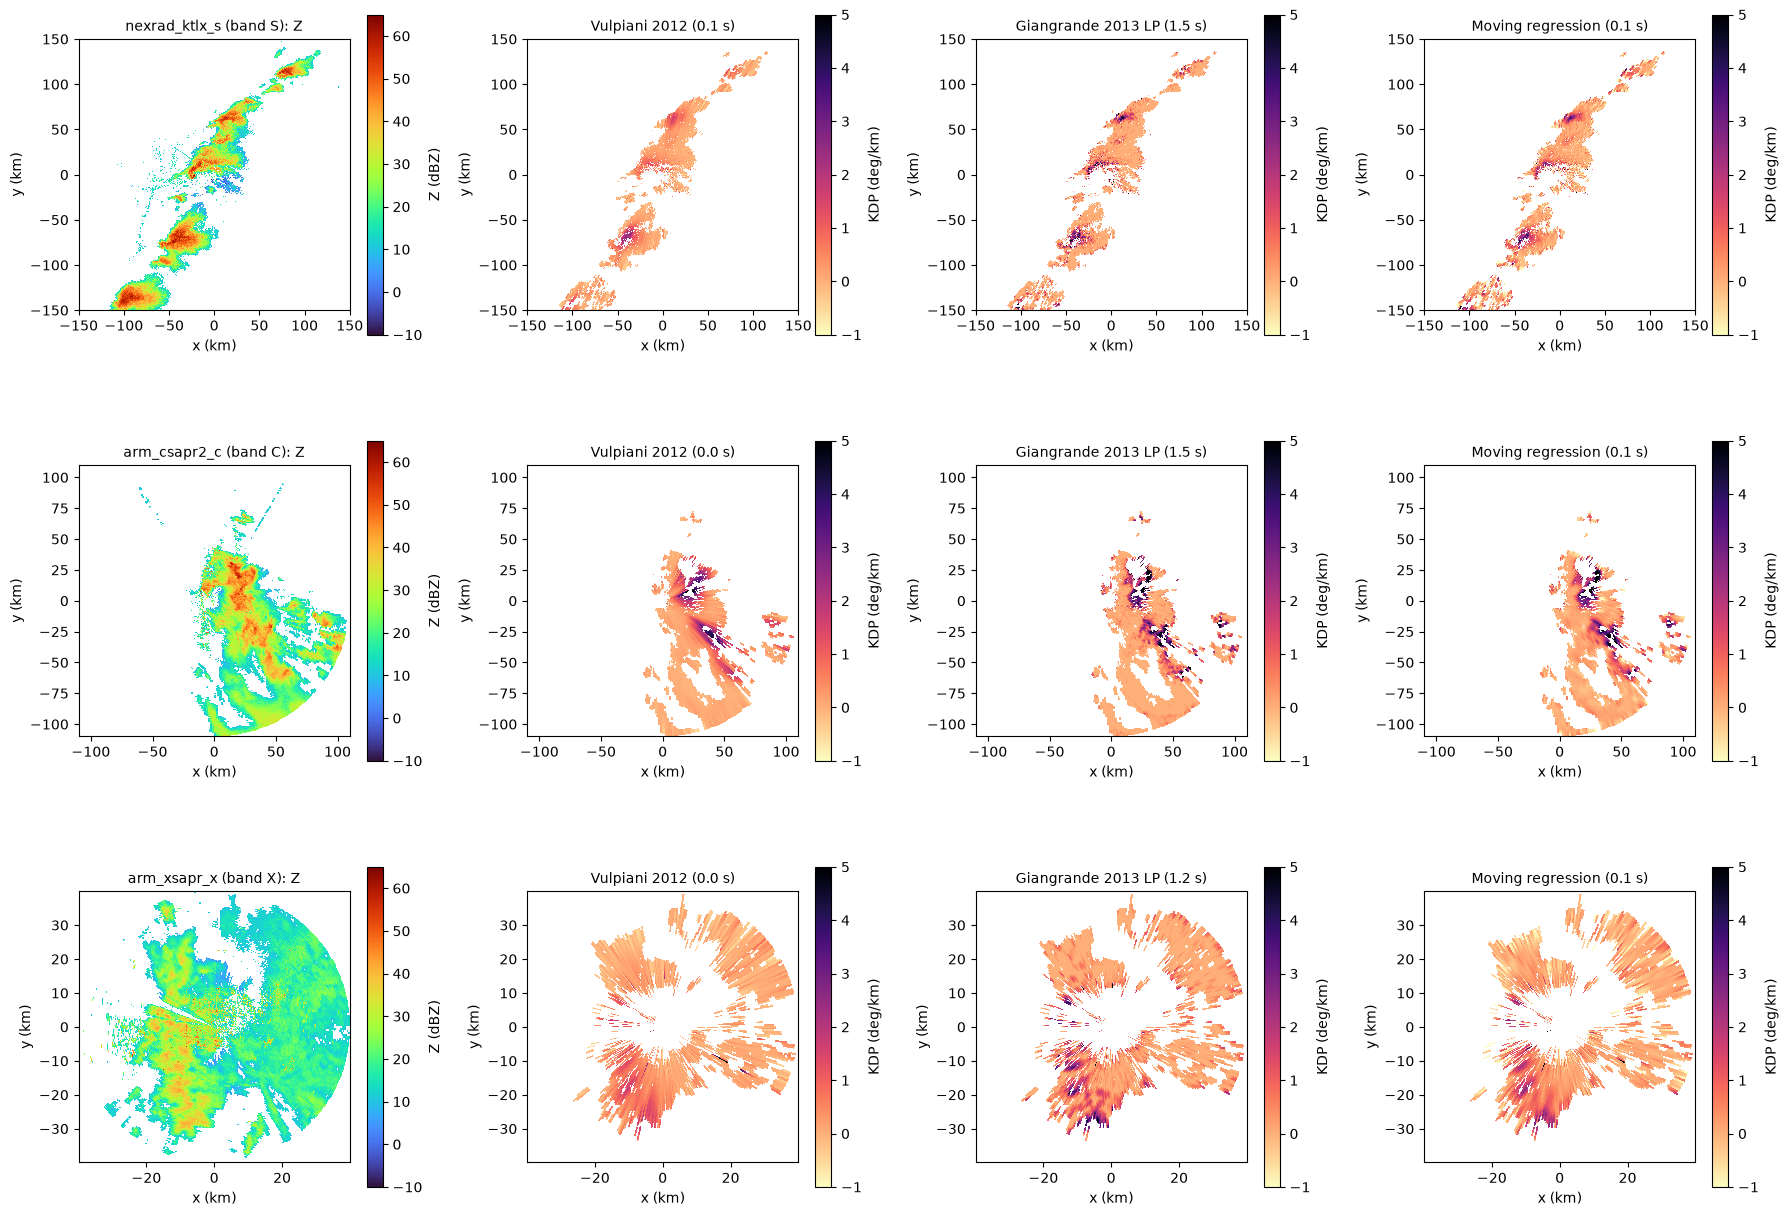

In [5]:
results, timing = {}, {}
for band, ds in data.items():
    for label, cls in METHODS.items():
        t = time.time()
        results[(band, label)] = cls()(ds, band=band)
        timing[(band, label)] = time.time() - t

fig, axes = plt.subplots(3, 4, figsize=(18, 13))
for row, (band, ds) in enumerate(data.items()):
    km = min(150.0, float(ds["range"].values[-1]) / 1e3)
    ppi(ds.assign(DBZH=ds["DBZH"].where(results[(band, "Vulpiani 2012")]["KDP"].notnull() | (ds["DBZH"] > 10))),
        "DBZH", ax=axes[row, 0], max_km=km, title=f"{samples[band]} (band {band}): Z")
    for col, label in enumerate(METHODS, start=1):
        ppi(results[(band, label)], "KDP", ax=axes[row, col], max_km=km, title=f"{label} ({timing[(band, label)]:.1f} s)")
fig.tight_layout()
fig.savefig(f"{FIG}/02_real_kdp_ppi.png", dpi=100)
plt.show()

## 3. Validation without truth: phase closure
Real data has no true KDP, and products from other processing chains are not truth either
(the ARM CSAPR2 file's own processed PHIDP rises only ~55° on the ray below, while the raw
PHIDP changes by ~100°). A physical check that any method must pass: along each ray,
**2 ∫ KDP dr = total PHIDP change**. We compare 2∫KDP with the PHIDP difference between the first
and last 10 valid gates of the prepared ray.

In [6]:
from radarwow.kdp.phase import prepare  # noqa: E402

rows = ["| band | method | rays | median abs closure error (deg) | 90th pct (deg) | runtime (s) |", "|---|---|---|---|---|---|"]
for band, ds in data.items():
    from radarwow.core import load_band
    psi, valid, _ = prepare(ds, load_band(band)["rhohv_rain_min"])
    dr = float(np.median(np.diff(ds["range"].values))) / 1e3
    for label in METHODS:
        k = results[(band, label)]["KDP"].values
        err = []
        for i in range(psi.shape[0]):
            idx = np.flatnonzero(valid[i])
            if idx.size < 40:
                continue
            dphi = np.median(psi[i, idx[-10:]]) - np.median(psi[i, idx[:10]])
            if dphi < 10:
                continue
            s, e = idx[5], idx[-5]
            err.append(abs(2 * np.nansum(np.where(np.isfinite(k[i, s:e]), k[i, s:e], 0)) * dr - (np.median(psi[i, idx[-10:]]) - np.median(psi[i, idx[:10]]))))
        err = np.asarray(err)
        rows.append(f"| {band} | {label} | {err.size} | {np.median(err):.1f} | {np.percentile(err, 90):.1f} | {timing[(band, label)]:.1f} |" if err.size else f"| {band} | {label} | 0 | - | - | - |")
display(Markdown("\n".join(rows)))

| band | method | rays | median abs closure error (deg) | 90th pct (deg) | runtime (s) |
|---|---|---|---|---|---|
| S | Vulpiani 2012 | 297 | 9.4 | 22.7 | 0.1 |
| S | Giangrande 2013 LP | 297 | 3.4 | 13.1 | 1.5 |
| S | Moving regression | 297 | 8.3 | 23.3 | 0.1 |
| C | Vulpiani 2012 | 156 | 16.3 | 74.3 | 0.0 |
| C | Giangrande 2013 LP | 156 | 8.7 | 78.2 | 1.5 |
| C | Moving regression | 156 | 16.6 | 80.2 | 0.1 |
| X | Vulpiani 2012 | 85 | 6.0 | 13.8 | 0.0 |
| X | Giangrande 2013 LP | 85 | 3.1 | 8.3 | 1.2 |
| X | Moving regression | 85 | 4.7 | 13.6 | 0.1 |

## 4. Inside one ray: C band (ARM CSAPR2) through a hail core

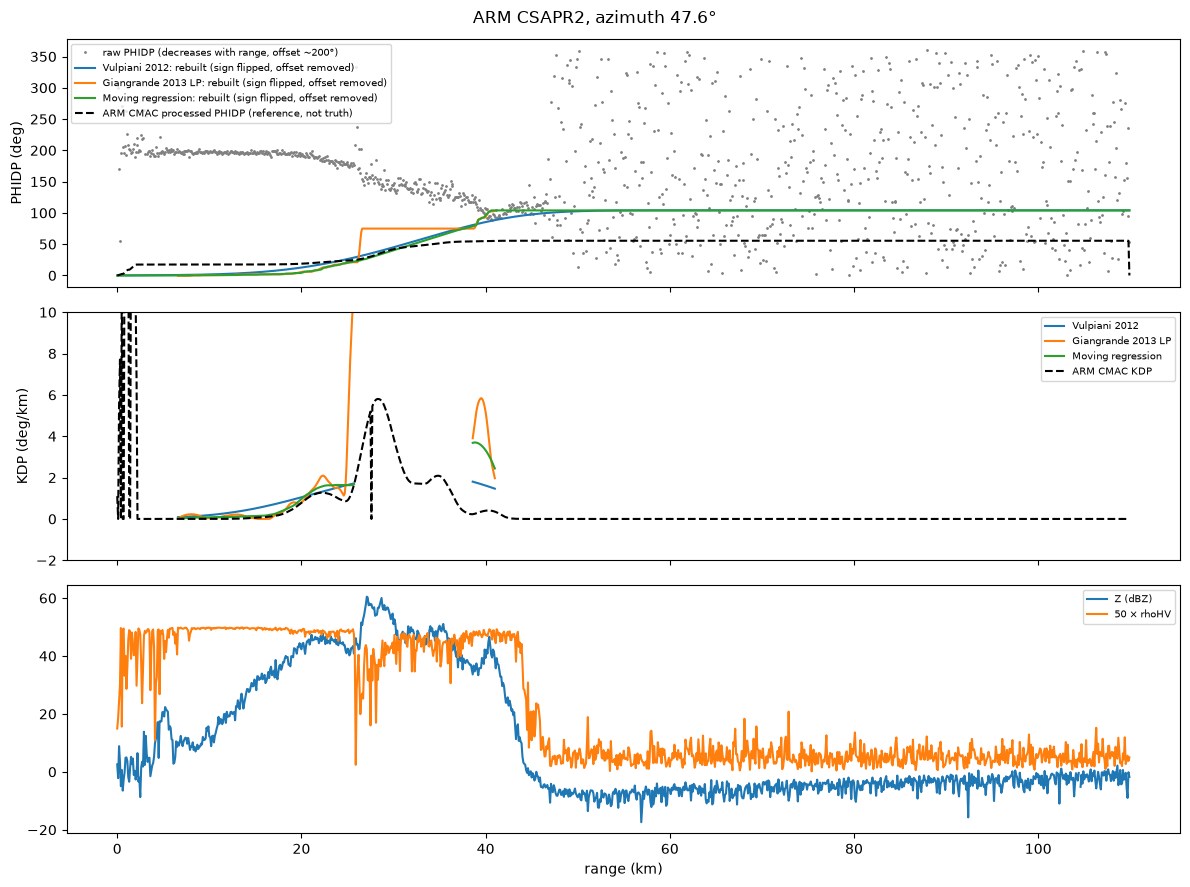

In [7]:
ds = data["C"]
ref = ds["filtered_corrected_differential_phase"].values
i = int(np.nanargmax(np.nanmax(ref, axis=1)))
r = ds["range"].values / 1e3
fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
ax[0].plot(r, ds["PHIDP"].values[i], ".", ms=2, color="grey", label="raw PHIDP (decreases with range, offset ~200°)")
for label in METHODS:
    ax[0].plot(r, results[("C", label)]["PHIDP_REC"].values[i], label=f"{label}: rebuilt (sign flipped, offset removed)")
ax[0].plot(r, ref[i], "k--", label="ARM CMAC processed PHIDP (reference, not truth)")
ax[0].set_ylabel("PHIDP (deg)")
ax[0].legend(fontsize=7)
for label in METHODS:
    ax[1].plot(r, results[("C", label)]["KDP"].values[i], label=label)
ax[1].plot(r, ds["filtered_corrected_specific_diff_phase"].values[i], "k--", label="ARM CMAC KDP")
ax[1].set_ylim(-2, 10)
ax[1].set_ylabel("KDP (deg/km)")
ax[1].legend(fontsize=7)
ax[2].plot(r, ds["DBZH"].values[i], label="Z (dBZ)")
ax[2].plot(r, 50 * ds["RHOHV"].values[i], label="50 × rhoHV")
ax[2].set_xlabel("range (km)")
ax[2].legend(fontsize=7)
fig.suptitle(f"ARM CSAPR2, azimuth {float(ds['azimuth'][i]):.1f}°")
fig.tight_layout()
fig.savefig(f"{FIG}/03_csapr2_ray.png", dpi=110)
plt.show()

## 5. Cross-check against Py-ART's Vulpiani implementation (S band)
Same paper, independent code: Py-ART `kdp_vulpiani` on the same NEXRAD sweep.


## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly supported
## by the U.S. Department of Energy Office of Science as part of
## the Atmospheric Radiation Measurement (ARM) User Facility.
##
## If you use this software to prepare a publication, please cite:
##
##     JJ Helmus and SM Collis, JORS 2016, doi: 10.5334/jors.119



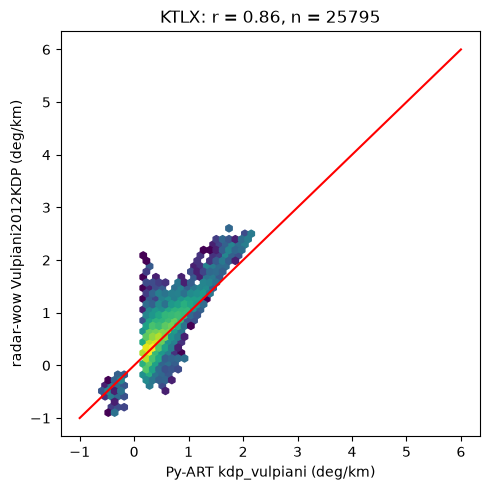

In [8]:
import pyart  # noqa: E402

from radarwow.core.data import fetch  # noqa: E402

path = fetch("nexrad_ktlx_s")
radar = pyart.io.read_nexrad_archive(path[:-3] if path.endswith(".gz") else path)
radar = radar.extract_sweeps([0])
gf = pyart.filters.GateFilter(radar)
gf.exclude_below("cross_correlation_ratio", 0.9)
gf.exclude_invalid("differential_phase")
kd, _ = pyart.retrieve.kdp_vulpiani(radar, gatefilter=gf, phidp_field="differential_phase", band="S",
                                    windsize=int(round(7.0 / 0.25)), n_iter=10)
k_pyart = np.ma.filled(kd["data"], np.nan).astype(float)
k_ours = results[("S", "Vulpiani 2012")]["KDP"].values
az_p = radar.azimuth["data"]
order = np.argsort(az_p)
k_pyart = k_pyart[order][:, : k_ours.shape[1]]
m = np.isfinite(k_ours) & np.isfinite(k_pyart) & (np.abs(k_pyart) > 0.2)
fig, ax = plt.subplots(figsize=(5, 5))
ax.hexbin(k_pyart[m], k_ours[m], gridsize=60, bins="log", extent=(-1, 6, -1, 6))
ax.plot([-1, 6], [-1, 6], "r")
ax.set(xlabel="Py-ART kdp_vulpiani (deg/km)", ylabel="radar-wow Vulpiani2012KDP (deg/km)",
       title=f"KTLX: r = {np.corrcoef(k_pyart[m], k_ours[m])[0, 1]:.2f}, n = {m.sum()}")
fig.tight_layout()
fig.savefig(f"{FIG}/04_vs_pyart.png", dpi=110)
plt.show()

## Takeaways
- **Source problems first:** S (NEXRAD) stores PHIDP 0-360° with folding; C (CSAPR2) stores it with
  the *opposite sign* and a ~200° offset; X (X-SAPR) keeps KDP in a variable named `diff_phase`.
  Without `open_volume` + `diagnose` + `prepare`, all three methods give nonsense on two of three radars.
- **Phase closure on real data:** LP is best on every band (median error 3-9°), at 10-60× the runtime.
  Vulpiani and moving regression close to 5-17°; C band (CSAPR2, hail) is hardest for all three.
- **Which gates count as rain matters as much as the method.** Two rules came out of this data:
  rain gates must form runs of at least 2 km, and have SNR >= 10 dB. Without them, weak echo and noise
  behind storms pass the rhoHV test by chance (NEXRAD rhoHV is unreliable at low SNR) and create fake
  PHIDP rises of tens to hundreds of degrees.
- **Synthetic truth:** moving regression has the lowest RMSE but goes strongly negative behind δ bumps;
  LP never goes negative.
- **Independent implementation:** our Vulpiani vs Py-ART `kdp_vulpiani` on KTLX gives r = 0.86 (0.70
  before the two rain-gate rules). The remaining scatter comes from gates the two codes mask and gap-fill
  differently.
- Validate with **phase closure** and independent implementations, not with another chain's product.